# Equiprobable successors — CE vs $\alpha$, train and test

Runs: `ICL-equiprobable-successors` (adam, lr 0.003, batch 256, init normal incl. the
unembedding, 2000 epochs, both architectures, 7 thresholds).
Data: this folder's `dataset/`, where each state's two successors are taken with probability
exactly 0.5 each.

Five curves per panel:

| curve | what it is |
|---|---|
| ideal-$\alpha$ | knows the true 2-successor table; puts $\alpha/2$ on each. The CE floor. |
| ctx-count | empirical successor counts $+\varepsilon$, renormalised, $\times\alpha$, plus the exact noise floor. A perfect induction head with a naive readout. |
| in-arch construction | the hand-built circuit running **inside** `SimplifiedTransformerMLP`: attention writes the counts, the frozen FFN turns them into $\log(f+\varepsilon)$ in place, `fc_out` selects, the model's own softmax normalises. Uses the identical log core the trained models were given. |
| separate / combined | the trained models, evaluated from their best-train checkpoints. |

Model CE is **recomputed from the checkpoints** on the full splits rather than read from
`best_train`, because the logged `best_train` is a running average of minibatch losses during an
epoch while every baseline here is a clean full-pass evaluation. `test_at_best` is already a
full-pass number and is printed alongside as a cross-check.

In [1]:
import csv, glob, importlib.util, json, os
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

CELL      = 'equi_opt-adam_lr-0.003_b-256_init-normal_ep-2000'
DATA_DIR  = 'dataset'
RUNS_DIR  = 'runs'
EPS       = 0.01
DEVICE    = 'cuda:1' if torch.cuda.is_available() else 'cpu'
FWD_BATCH = 256
USE_CACHE = True

plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 170,
    'font.size': 13, 'axes.titlesize': 14, 'axes.labelsize': 13,
    'xtick.labelsize': 12, 'ytick.labelsize': 12, 'legend.fontsize': 11.5,
    'figure.titlesize': 16, 'axes.grid': True, 'grid.alpha': 0.25,
    'axes.spines.top': False, 'axes.spines.right': False,
    'lines.linewidth': 2.0, 'legend.frameon': False,
})

_spec = importlib.util.spec_from_file_location('tw', 'train_with_equiprobable.py')
TW = importlib.util.module_from_spec(_spec); _spec.loader.exec_module(TW)
Model = TW.SimplifiedTransformerMLP

DEV = torch.device(DEVICE)
CDIR = os.path.join(RUNS_DIR, CELL)
ART  = os.path.join('artifacts', CELL)
os.makedirs(ART, exist_ok=True)

CKPT = {}
for p in sorted(glob.glob(os.path.join(CDIR, 'model_*.pth'))):
    stem = os.path.basename(p)[6:-4]
    arch, rest = stem.split('_seed', 1)
    CKPT[(arch, float(rest.split('_x_')[1]))] = (p, os.path.join(CDIR, f'metrics_{stem}.json'))
ARCHS = sorted({a for a, _ in CKPT})
THRS  = sorted({t for _, t in CKPT})
SPLITS = ['train', 'test']

_cfg = json.load(open(CKPT[(ARCHS[0], THRS[0])][1]))['config']
V, VS, T = _cfg['v_sig'] + _cfg['n_noise'], _cfg['v_sig'], _cfg['seq_len']
N_NOISE  = V - VS
TS, TE   = _cfg['token_start'], T

def load_blob(split, thr):
    return torch.load(os.path.join(DATA_DIR, split, f'data_x_{thr}.pt'), weights_only=False)

for thr in THRS:
    assert load_blob('test', thr).get('succ_split') == 'equiprobable', thr

print(f'cell    : {CELL}')
print(f'config  : {_cfg["optimizer"]} lr={_cfg["lr"]} b={_cfg["batch_size"]} '
      f'init={_cfg["init"]} epochs={_cfg["epochs"]}  frozen-log delta={_cfg["freeze_delta"]}')
print(f'archs   : {ARCHS}   thresholds: {THRS}')
print(f'vocab   : V={V} (signal {VS} + noise {N_NOISE}), seq_len={T}, window [{TS}:{TE}]')
print(f'sizes   : train {load_blob("train", THRS[0])["x"].shape[0]}, '
      f'test {load_blob("test", THRS[0])["x"].shape[0]} sequences')
print(f'device  : {DEV}')

cell    : equi_opt-adam_lr-0.003_b-256_init-normal_ep-2000
config  : adam lr=0.003 b=256 init=normal epochs=2000  frozen-log delta=0.01
archs   : ['combined', 'separate']   thresholds: [0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
vocab   : V=8 (signal 4 + noise 4), seq_len=100, window [50:100]
sizes   : train 25000, test 10000 sequences
device  : cuda:1


## Reference predictors

In [2]:
def ideal_alpha_dist(blob, alpha):
    x = blob['x'].numpy(); trans = blob['transitions']; probs = blob['trans_probs']
    B = x.shape[0]; W = TE - TS
    tarr = np.array([[trans[b][v] for v in range(VS)] for b in range(B)], dtype=np.int64)
    parr = np.array([[probs[b][v] for v in range(VS)] for b in range(B)], dtype=np.float64)
    out = np.zeros((B, W, V)); last = np.zeros(B, dtype=np.int64); ar = np.arange(B)
    for t in range(TE):
        sig = x[:, t] < VS
        last = np.where(sig, x[:, t], last)
        if t < TS:
            continue
        p = np.zeros((B, V)); p[:, VS:] = (1.0 - alpha) / N_NOISE
        for j in (0, 1):
            p[ar, tarr[ar, last, j]] += alpha * parr[ar, last, j]
        out[:, t - TS] = p
    return out


def _counter(x):
    B = x.shape[0]
    counts = np.zeros((B, V, VS)); pending = np.zeros((B, V))
    last = np.full(B, -1, dtype=np.int64)

    def step(col):
        tok = x[:, col]; sig = tok < VS
        ri = np.where(sig)[0]
        if len(ri):
            rt = tok[ri]
            oh = (np.arange(VS) == rt[:, None]).astype(np.float64)
            np.add.at(counts, ri, pending[ri, :, None] * oh[:, None, :])
            pending[ri, :] = 0.0; pending[ri, rt] = 1.0; last[ri] = rt
        ni = np.where(~sig)[0]
        if len(ni):
            pending[ni, tok[ni]] += 1.0
    return counts, last, step


def ctx_count_dist(blob, alpha, eps=EPS):
    x = blob['x'].numpy(); B = x.shape[0]; W = TE - TS
    counts, last, step = _counter(x)
    for i in range(TS):
        step(i)
    out = np.zeros((B, W, V))
    for t in range(TS, TE):
        v = x[:, t]
        q = np.where(v < VS, v, np.maximum(last, 0))
        c = counts[np.arange(B), q] + eps
        p = np.zeros((B, V))
        p[:, :VS] = c / c.sum(axis=1, keepdims=True) * alpha
        p[:, VS:] = (1.0 - alpha) / N_NOISE
        out[:, t - TS] = p
        step(t)
    return out


def ce_from_dist(p, y):
    yw = y[:, TS:TE]; B, W = yw.shape
    return float(-np.log(np.maximum(p[np.arange(B)[:, None], np.arange(W)[None, :], yw],
                                    1e-12)).mean())

## In-architecture construction

Identical to the trained models in every respect except that its attention and readout are
hand-set: layer-1/2 implement the perfect induction circuit, `ff1`/`ff2` hold the **same frozen
log core** the runs were trained with (`fit_log_core(0.01, 128, 40.0, 32.0)`), `fc_out` is the
identity selector on the count slots, and the noise logit is one constant.

Layer-2 attention is a softmax average, so $\sum_v f_v \equiv 1$ and a single bias
$\log\frac{(1+V_{sig}\varepsilon)(1-\alpha)}{\alpha\,n_{noise}}$ makes the model's own softmax
return exactly $\alpha(f_v+\varepsilon)/(1+V_{sig}\varepsilon)$ on the signal tokens and
$(1-\alpha)/n_{noise}$ on the noise tokens. Both facts are asserted below.

In [4]:
@torch.no_grad()
def model_ce(model, blob, batch=FWD_BATCH):
    x, y = blob['x'], blob['y']
    tot, n = 0.0, 0
    for i in range(0, x.shape[0], batch):
        xb = x[i:i + batch].to(DEV); yb = y[i:i + batch, TS:TE].to(DEV)
        logits = model(xb)[:, TS:TE]
        tot += F.cross_entropy(logits.reshape(-1, V), yb.reshape(-1), reduction='sum').item()
        n += yb.numel()
    return tot / n


def load_trained(arch, thr):
    m = Model(V, T, V + T, VS, K_LOG, True, arch).to(DEV)
    m.load_state_dict(torch.load(CKPT[(arch, thr)][0], map_location=DEV, weights_only=True))
    m.eval()
    return m

## Compute every value

In [5]:
CACHE = os.path.join(ART, 'curves.json')
cache = json.load(open(CACHE)) if (USE_CACHE and os.path.exists(CACHE)) else {}
KEYS = ['ideal', 'ctx', 'construction'] + ARCHS

CE = {s: {k: [] for k in KEYS} for s in SPLITS}
for split in SPLITS:
    for thr in THRS:
        ck = f'{split}|{thr}|eps{EPS}'
        if ck not in cache:
            blob = load_blob(split, thr); y = blob['y'].numpy()
            e = {'ideal': ce_from_dist(ideal_alpha_dist(blob, thr), y),
                 'ctx':   ce_from_dist(ctx_count_dist(blob, thr), y),
                 'construction': model_ce(build_construction(thr), blob)}
            for a in ARCHS:
                e[a] = model_ce(load_trained(a, thr), blob)
            cache[ck] = e
            json.dump(cache, open(CACHE, 'w'), indent=2)
        e = cache[ck]
        for k in KEYS:
            CE[split][k].append(e[k])
        print(f'{split:5s} thr={thr}  ' + '  '.join(f'{k}={e[k]:.4f}' for k in KEYS), flush=True)

for split in SPLITS:
    for i, thr in enumerate(THRS):
        assert CE[split]['ideal'][i] <= CE[split]['ctx'][i] + 1e-6, (split, thr)
print('\nideal-alpha is below ctx-count at every threshold on both splits.')

print('\ncheckpoint test CE vs the test_at_best logged during training:')
for a in ARCHS:
    d = [CE['test'][a][i] - json.load(open(CKPT[(a, t)][1]))['test_at_best']
         for i, t in enumerate(THRS)]
    print(f'  {a:9s} max|diff| = {max(abs(v) for v in d):.2e}')

train thr=0.4  ideal=1.7822  ctx=1.8442  construction=1.8439  combined=1.8160  separate=1.8002
train thr=0.5  ideal=1.7328  ctx=1.7850  construction=1.7888  combined=1.7592  separate=1.7424
train thr=0.6  ideal=1.6436  ctx=1.6890  construction=1.6968  combined=1.6613  separate=1.6496
train thr=0.7  ideal=1.5118  ctx=1.5523  construction=1.5636  combined=1.5202  separate=1.5150
train thr=0.8  ideal=1.3324  ctx=1.3701  construction=1.3842  combined=1.3391  separate=1.3347
train thr=0.9  ideal=1.0884  ctx=1.1234  construction=1.1404  combined=1.0949  separate=1.0903
train thr=1.0  ideal=0.6931  ctx=0.7265  construction=0.7462  combined=0.6910  separate=0.6930
test  thr=0.4  ideal=1.7822  ctx=1.8444  construction=1.8436  combined=1.8788  separate=1.8158
test  thr=0.5  ideal=1.7330  ctx=1.7856  construction=1.7899  combined=1.8125  separate=1.7707
test  thr=0.6  ideal=1.6428  ctx=1.6891  construction=1.6969  combined=1.7083  separate=1.6727
test  thr=0.7  ideal=1.5117  ctx=1.5518  construct

## CE vs $\alpha$ — train and test

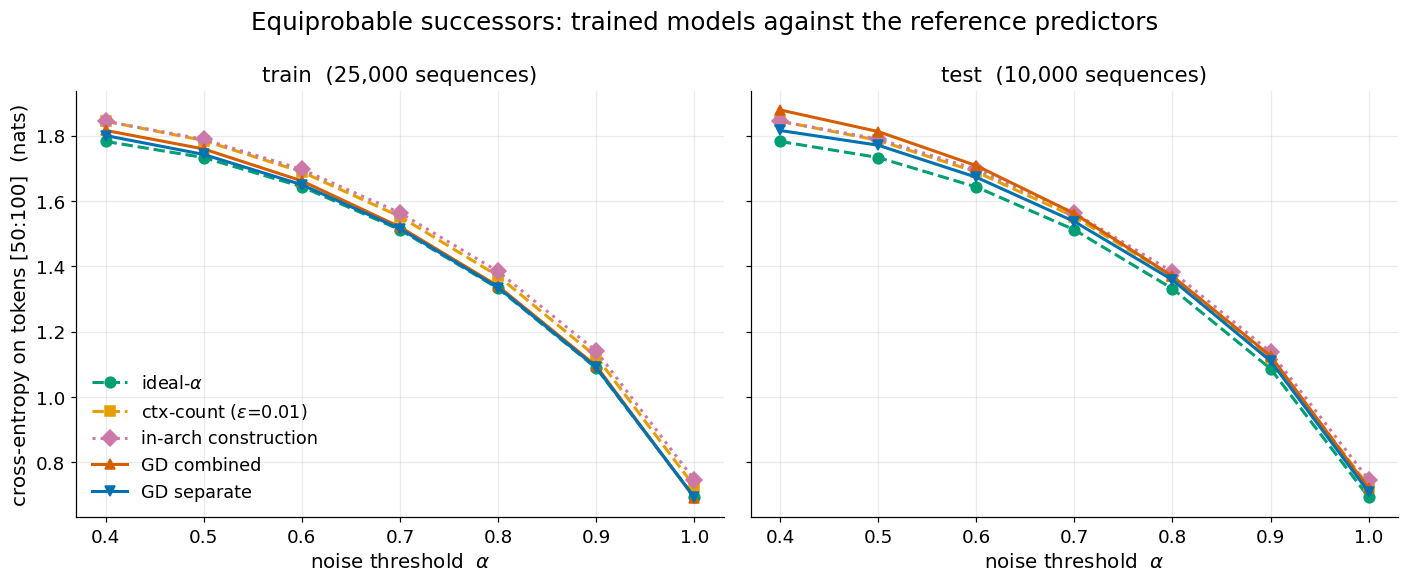

In [6]:
SERIES = {
    'ideal':        dict(color='#009E73', marker='o', ls='--', label=r'ideal-$\alpha$'),
    'ctx':          dict(color='#E69F00', marker='s', ls='--',
                         label=rf'ctx-count ($\varepsilon$={EPS})'),
    'construction': dict(color='#CC79A7', marker='D', ls=':',
                         label='in-arch construction'),
    'separate':     dict(color='#0072B2', marker='v', ls='-', label='GD separate'),
    'combined':     dict(color='#D55E00', marker='^', ls='-', label='GD combined'),
}
ORDER = ['ideal', 'ctx', 'construction'] + ARCHS

fig, axes = plt.subplots(1, 2, figsize=(13.0, 5.4), sharey=True)
for ax, split in zip(axes, SPLITS):
    for k in ORDER:
        st = SERIES[k]
        ax.plot(THRS, CE[split][k], color=st['color'], marker=st['marker'], ls=st['ls'],
                ms=7, label=st['label'])
    n = load_blob(split, THRS[0])['x'].shape[0]
    ax.set_title(f'{split}  ({n:,} sequences)')
    ax.set_xlabel(r'noise threshold  $\alpha$')
    ax.set_xticks(THRS)
axes[0].set_ylabel(f'cross-entropy on tokens [{TS}:{TE}]  (nats)')
axes[0].legend(loc='lower left')
fig.suptitle('Equiprobable successors: trained models against the reference predictors')
fig.tight_layout()
fig.savefig(os.path.join(ART, 'ce_vs_alpha.png'), bbox_inches='tight')
plt.show()

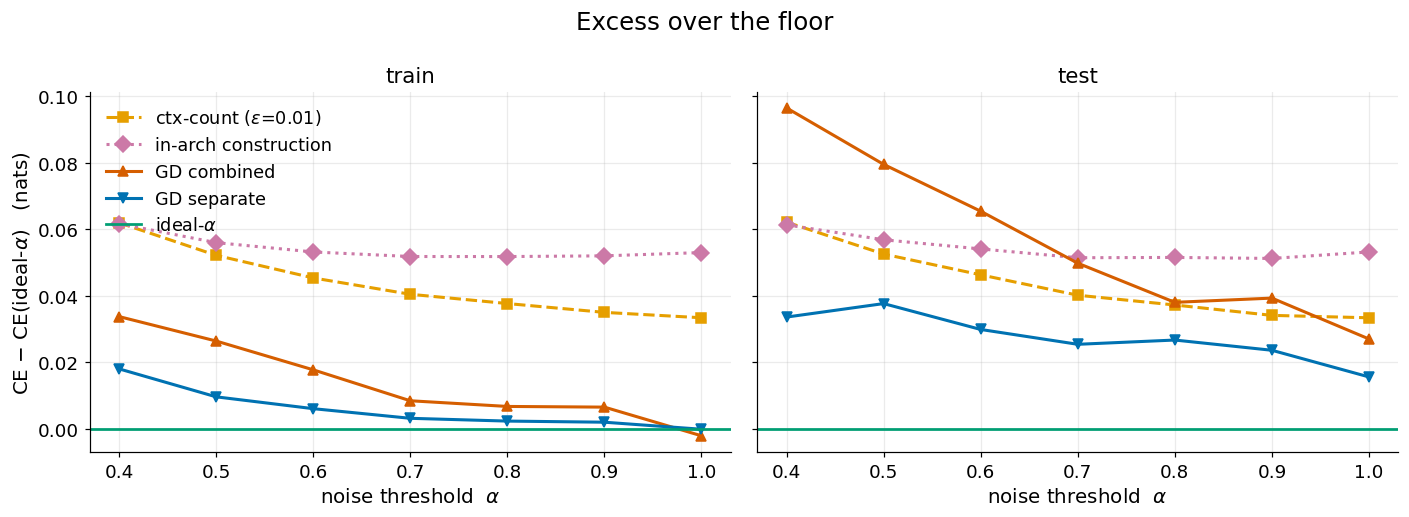

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13.0, 4.8), sharey=True)
for ax, split in zip(axes, SPLITS):
    base = np.array(CE[split]['ideal'])
    for k in ORDER[1:]:
        st = SERIES[k]
        ax.plot(THRS, np.array(CE[split][k]) - base, color=st['color'], marker=st['marker'],
                ls=st['ls'], ms=7, label=st['label'])
    ax.axhline(0, color=SERIES['ideal']['color'], lw=1.8, label=SERIES['ideal']['label'])
    ax.set_title(split)
    ax.set_xlabel(r'noise threshold  $\alpha$')
    ax.set_xticks(THRS)
axes[0].set_ylabel(r'CE $-$ CE(ideal-$\alpha$)   (nats)')
axes[0].legend(loc='upper left')
fig.suptitle('Excess over the floor')
fig.tight_layout()
fig.savefig(os.path.join(ART, 'excess_ce.png'), bbox_inches='tight')
plt.show()

## Exact plotted values

In [8]:
LBL = {'ideal': 'ideal', 'ctx': 'ctx-count', 'construction': 'construction',
       'separate': 'separate', 'combined': 'combined'}
hdr = f'{"thr":>5s} | ' + ' | '.join(f'{LBL[k]:>21s}' for k in ORDER)
print(hdr)
print(f'{"":>5s} | ' + ' | '.join(f'{"train":>10s} {"test":>10s}' for _ in ORDER))
print('-' * len(hdr))
rows = []
for i, thr in enumerate(THRS):
    r = {'threshold': thr}
    for k in ORDER:
        r[f'{k}_train'] = round(CE['train'][k][i], 5)
        r[f'{k}_test'] = round(CE['test'][k][i], 5)
    rows.append(r)
    print(f'{thr:5.1f} | ' + ' | '.join(
        f'{CE["train"][k][i]:10.4f} {CE["test"][k][i]:10.4f}' for k in ORDER))

path = os.path.join(ART, 'ce_vs_alpha.csv')
with open(path, 'w', newline='') as fh:
    w = csv.DictWriter(fh, fieldnames=list(rows[0])); w.writeheader(); w.writerows(rows)
print(f'\nwrote {path}')

  thr |                 ideal |             ctx-count |          construction |              combined |              separate
      |      train       test |      train       test |      train       test |      train       test |      train       test
-----------------------------------------------------------------------------------------------------------------------------
  0.4 |     1.7822     1.7822 |     1.8442     1.8444 |     1.8439     1.8436 |     1.8160     1.8788 |     1.8002     1.8158
  0.5 |     1.7328     1.7330 |     1.7850     1.7856 |     1.7888     1.7899 |     1.7592     1.8125 |     1.7424     1.7707
  0.6 |     1.6436     1.6428 |     1.6890     1.6891 |     1.6968     1.6969 |     1.6613     1.7083 |     1.6496     1.6727
  0.7 |     1.5118     1.5117 |     1.5523     1.5518 |     1.5636     1.5631 |     1.5202     1.5615 |     1.5150     1.5371
  0.8 |     1.3324     1.3315 |     1.3701     1.3687 |     1.3842     1.3830 |     1.3391     1.3695 |     1.3347    

In [ ]:
print('combined - separate  (positive = separate is better):')
for split in SPLITS:
    d = np.array(CE[split]['combined']) - np.array(CE[split]['separate'])
    print(f'  {split:5s} ' + '  '.join(f'{t}:{v:+.4f}' for t, v in zip(THRS, d)) +
          f'   | mean {d.mean():+.4f}  wins {int((d > 0).sum())}/{len(d)}')

print('\nmodel - ctx-count  (negative = the model beats a perfect induction head):')
for split in SPLITS:
    for a in ARCHS:
        d = np.array(CE[split][a]) - np.array(CE[split]['ctx'])
        print(f'  {split:5s} {a:9s} ' + '  '.join(f'{t}:{v:+.4f}' for t, v in zip(THRS, d)))

print('\nmodel - in-arch construction:')
for split in SPLITS:
    for a in ARCHS:
        d = np.array(CE[split][a]) - np.array(CE[split]['construction'])
        print(f'  {split:5s} {a:9s} ' + '  '.join(f'{t}:{v:+.4f}' for t, v in zip(THRS, d)))

print('\nexcess over ideal-alpha, mean across thresholds:')
for split in SPLITS:
    print(f'  {split:5s} ' + '  '.join(
        f'{LBL[k]}={np.mean(np.array(CE[split][k]) - np.array(CE[split]["ideal"])):+.4f}'
        for k in ORDER[1:]))
    

combined - separate  (positive = separate is better):
  train 0.4:+0.0157  0.5:+0.0168  0.6:+0.0117  0.7:+0.0053  0.8:+0.0044  0.9:+0.0045  1.0:-0.0020   | mean +0.0081  wins 6/7
  test  0.4:+0.0629  0.5:+0.0419  0.6:+0.0356  0.7:+0.0244  0.8:+0.0113  0.9:+0.0157  1.0:+0.0114   | mean +0.0290  wins 7/7

model - ctx-count  (negative = the model beats a perfect induction head):
  train combined  0.4:-0.0282  0.5:-0.0258  0.6:-0.0276  0.7:-0.0320  0.8:-0.0310  0.9:-0.0285  1.0:-0.0355
  train separate  0.4:-0.0440  0.5:-0.0426  0.6:-0.0393  0.7:-0.0373  0.8:-0.0354  0.9:-0.0330  1.0:-0.0335
  test  combined  0.4:+0.0344  0.5:+0.0270  0.6:+0.0191  0.7:+0.0096  0.8:+0.0008  0.9:+0.0052  1.0:-0.0064
  test  separate  0.4:-0.0286  0.5:-0.0149  0.6:-0.0164  0.7:-0.0148  0.8:-0.0105  0.9:-0.0105  1.0:-0.0178

model - in-arch construction:
  train combined  0.4:-0.0279  0.5:-0.0296  0.6:-0.0355  0.7:-0.0434  0.8:-0.0451  0.9:-0.0455  1.0:-0.0551
  train separate  0.4:-0.0437  0.5:-0.0464  0.6:-0